<div style="border:1px solid #d8e2ef; border-radius:18px; padding:26px 30px; background:#ffffff;">
  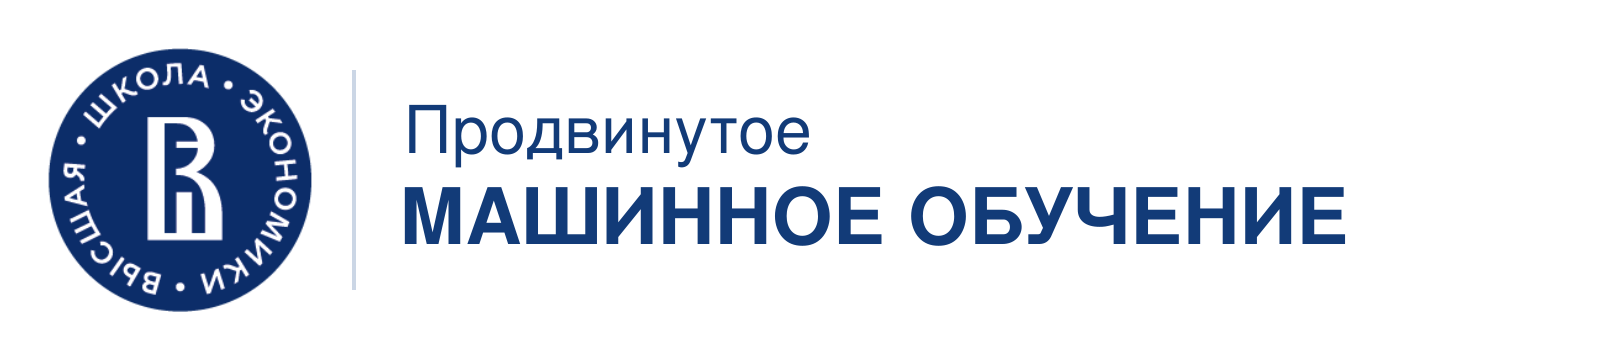

# Бонусное задание №3
## Градиентный бустинг: геометрия и функция потерь
</div>


Два небольших задания по лекции №4. Используем готовый бустинг из `sklearn`.

**Ваша работа:** в первом задании изменить глубину дерева и объяснить рисунки; во втором — вывести простую производную и дописать одну функцию. Обучение моделей и построение графиков уже подготовлены.

**Что сдать:** ноутбук с графиками для двух глубин, реализованной функцией и короткими ответами на вопросы. Достаточно 2–3 предложений на каждый вопрос.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import plot_tree
from IPython.display import display

SEED = 42
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


## 1. Всегда ли дерево делит пространство на две области? ($0,5$ балла)

У объектов два признака: $x_1$ и $x_2$. Построим ансамбль из **трёх деревьев** для квадратичной потери. На каждом шаге новое дерево обучается исправлять ошибки текущего ансамбля.

**Что сделать:**

1. Запустите готовую ячейку визуализации ниже.
2. Запустите `show_boosting(depth=1)` и рассмотрите все три шага.
3. Во второй ячейке вызова замените глубину 1 на 2 и запустите её. Сохраните оба результата.

**Как читать рисунок:** слева — поправка нового дерева **до** умножения на learning rate; чёрные линии показывают его разбиения. Справа — прогноз ансамбля после добавления этого дерева. Это разные величины:
$$F_m(x)=F_{m-1}(x)+0.5\,T_m(x).$$
Число листьев и выбранные пороги появятся в таблице. Код визуализации изменять не нужно.


In [3]:
#@title Готовая визуализация: выполните эту ячейку, дописывать её не нужно.
rng = np.random.default_rng(SEED)
X = rng.uniform(-1, 1, (240, 2))
y = 3.0 * (X[:, 0] > 0) + 2.0 * (X[:, 1] > 0.15)
axis = np.linspace(-1, 1, 180)
g1, g2 = np.meshgrid(axis, axis)
grid = np.column_stack([g1.ravel(), g2.ravel()])


def draw_splits(ax, tree):
    # Рисуем каждую границу только внутри соответствующего узла.
    t = tree.tree_
    def visit(node, x0, x1, y0, y1):
        if t.children_left[node] == -1:
            return
        feature, threshold = t.feature[node], t.threshold[node]
        if feature == 0:
            ax.plot([threshold, threshold], [y0, y1], 'k-', lw=1)
            visit(t.children_left[node], x0, threshold, y0, y1)
            visit(t.children_right[node], threshold, x1, y0, y1)
        else:
            ax.plot([x0, x1], [threshold, threshold], 'k-', lw=1)
            visit(t.children_left[node], x0, x1, y0, threshold)
            visit(t.children_right[node], x0, x1, threshold, y1)
    visit(0, -1, 1, -1, 1)


def show_boosting(depth):
    model = GradientBoostingRegressor(
        loss='squared_error', n_estimators=3, max_depth=depth,
        learning_rate=0.5, random_state=SEED,
    ).fit(X, y)
    stages = list(model.staged_predict(grid))
    trees = model.estimators_[:, 0]
    corrections = [tree.predict(grid) for tree in trees]
    bound = max(np.abs(values).max() for values in corrections)
    fig, axes = plt.subplots(3, 2, figsize=(9, 10), constrained_layout=True)
    rows = []
    for m, (tree, correction, prediction) in enumerate(zip(trees, corrections, stages)):
        for col, (values, title) in enumerate([
            (correction, f'Шаг {m+1}: новое дерево, листьев {tree.get_n_leaves()}'),
            (prediction, f'Шаг {m+1}: весь ансамбль'),
        ]):
            ax = axes[m, col]
            im = ax.pcolormesh(g1, g2, values.reshape(g1.shape), shading='auto',
                cmap='coolwarm' if col == 0 else 'viridis',
                vmin=-bound if col == 0 else 0, vmax=bound if col == 0 else 5)
            ax.set(xlabel='$x_1$', ylabel='$x_2$', title=title, aspect='equal')
            fig.colorbar(im, ax=ax, shrink=0.7)
        draw_splits(axes[m, 0], tree)
        t = tree.tree_
        nodes = np.flatnonzero(t.children_left != -1)
        rows.append({'Шаг': m+1, 'Листьев нового дерева': tree.get_n_leaves(),
            'Разбиения': '; '.join(f'x{t.feature[j]+1} <= {t.threshold[j]:.3f}' for j in nodes)})
    fig.suptitle(f'max_depth = {depth}', fontsize=14)
    plt.show()
    display(pd.DataFrame(rows))
    if depth == 2:
        fig, ax = plt.subplots(figsize=(10, 4))
        plot_tree(trees[0], feature_names=['x1', 'x2'], impurity=False,
                  filled=True, rounded=True, precision=2, ax=ax)
        ax.set_title('Первое дерево глубины 2: сравните узлы с областями на плоскости')
        plt.tight_layout()
        plt.show()
    return model


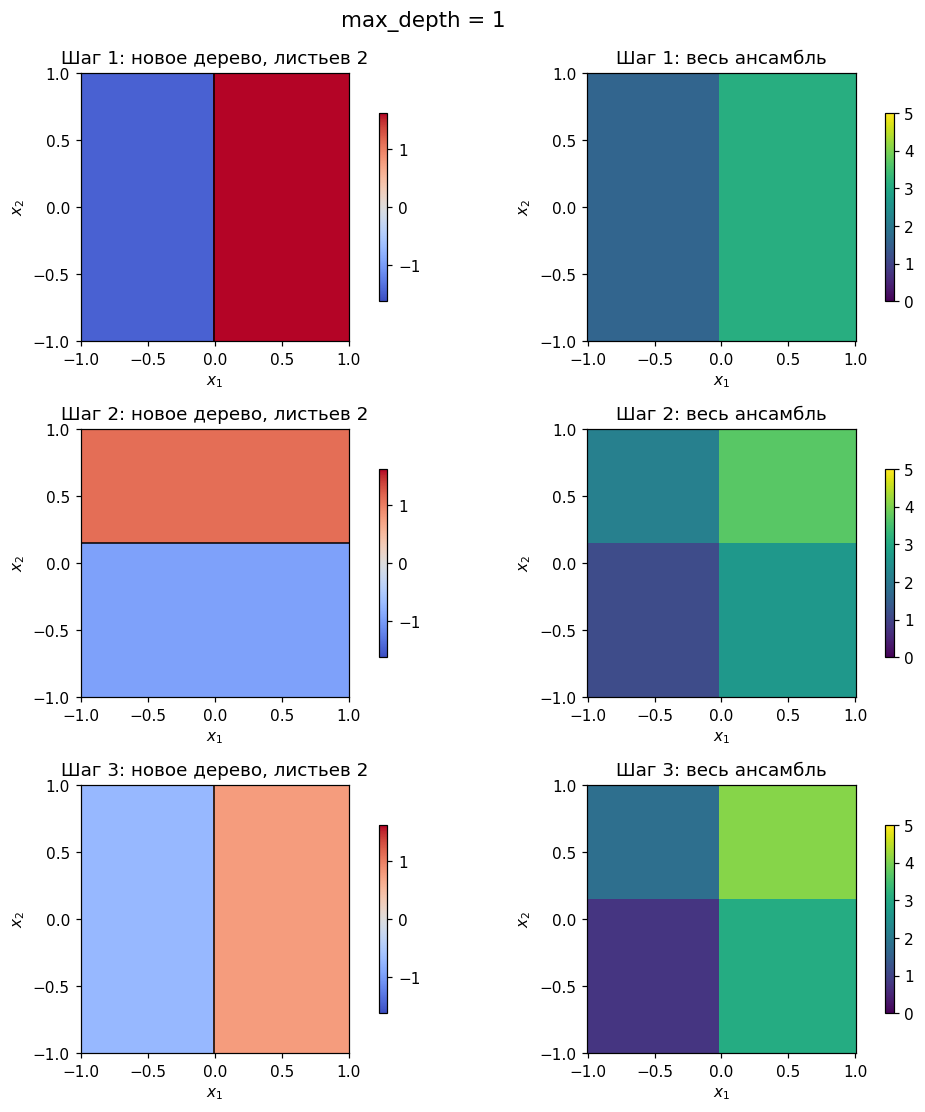

,Шаг,Листьев нового дерева,Разбиения
0,1,2,x1 <= -0.007
1,2,2,x2 <= 0.152
2,3,2,x1 <= -0.007


In [4]:
model_depth1 = show_boosting(depth=1)


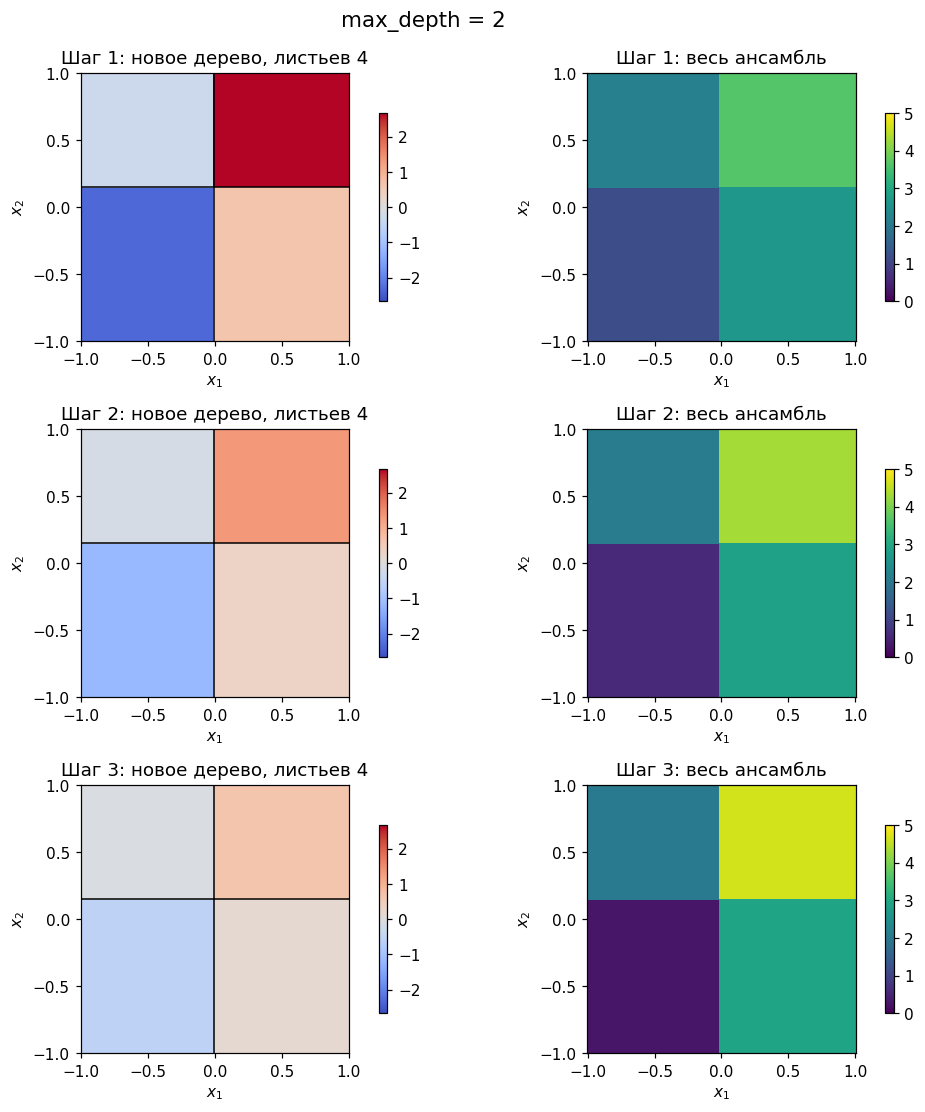

,Шаг,Листьев нового дерева,Разбиения
0,1,4,x1 <= -0.007; x2 <= 0.148; x2 <= 0.154
1,2,4,x1 <= -0.007; x2 <= 0.148; x2 <= 0.154
2,3,4,x1 <= -0.007; x2 <= 0.148; x2 <= 0.154


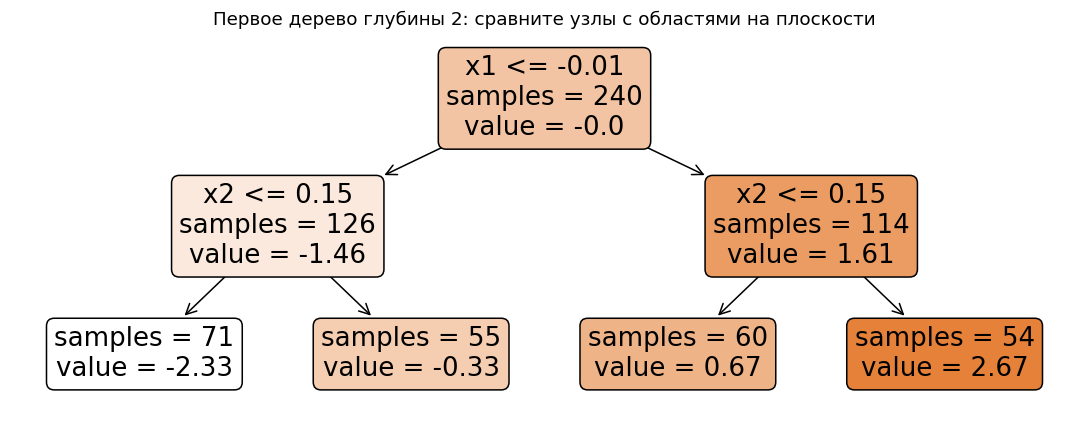

In [5]:
# Измените только depth на 2 и запустите эту ячейку.
model_depth2 = show_boosting(depth=2)


**Ответьте по рисункам и таблицам:**

На лекции мы с вами обсудили, что в нашем случае (когда используем решающие пни, как базовые модели) на каждом шаге деревом (пнем) будет выделяться максимум 2 области (2 листа). Для решающих пней, как базовых моделей, это верно всегда - максимум 2 листа. Но какие есть случаи, при которых мы столкнемся с более сложным разбиением на каждом шаге? Давайте для этого поподробнее ответим на следующие вопросы, а в конце сделайте общий вывод-заключение к данному эксперименту.

1. Сколько областей выделяет первое дерево при глубине 1 и при глубине 2? Почему у бинарного дерева может быть больше двух листьев?
2. Как направлены границы относительно осей? Может ли одно такое разбиение узла провести наклонную прямую?
3. Обязательно ли следующее дерево выбирает новые границы? Найдите повторение или изменение признака и порога в своих таблицах.
4. Чем рисунок нового дерева отличается от рисунка всего ансамбля? Используйте формулу обновления из условия.

**Ваши ответы:** …


## 2. А если ошибка измеряется модулем? ($0,5$ балла)

Для квадратичной потери $L(y,F)=\frac12(y-F)^2$ псевдоостаток равен обычной ошибке $y-F$. Теперь возьмём **абсолютную ошибку**:
$$L(y,F)=|y-F|.$$

**Что сделать:**

1. Найдите $r=-\frac{\partial L}{\partial F}$ отдельно при $y>F$ и $y<F$. Подсказка: раскройте модуль в каждом случае и продифференцируйте **по $F$**.
2. Реализуйте функцию ниже по полученной формуле. При $y=F$ производной нет; для этого упражнения принимаем $r=0$ — допустимое значение отрицательного субградиента. Доказывать это не требуется.
3. Запустите проверки, таблицу и готовый эксперимент с двумя функциями потерь.

**Ваш вывод производной:** …


In [ ]:
def absolute_pseudo(y, prediction):
    y = np.asarray(y, dtype=float)
    prediction = np.asarray(prediction, dtype=float)
    # TODO: верните массив псевдоостатков по выведенной формуле.
    # Можно использовать np.where или np.sign; при равенстве верните 0.
    return None


ready = absolute_pseudo([3., -2., 1.], [1., 1., 1.]) is not None
if ready:
    assert np.allclose(absolute_pseudo([3., -2., 1.], [1., 1., 1.]), [1., -1., 0.])
    assert np.allclose(absolute_pseudo([20., -50.], [0., 0.]), [1., -1.])
    print('Обе проверки пройдены, вы молодец!! Great job:)')
    errors = np.array([-8., -2., -0.3, 0., 0.3, 2., 8.])
    display(pd.DataFrame({
        'Обычная ошибка y-F': errors,
        'Псевдоостаток: квадратичная потеря': errors,
        'Псевдоостаток: абсолютная потеря': absolute_pseudo(errors, np.zeros_like(errors)),
    }))
else:
    print('Сначала допишите absolute_pseudo и снова запустите ячейку.')


**Готовый эксперимент.** Есть плавная зависимость и несколько сильно завышенных откликов — выбросов. Обучим два ансамбля на одинаковых данных и с одинаковыми настройками деревьев; поменяем только loss.

Ваша функция выше нужна для изучения псевдоостатков. Модели ниже используют встроенные функции потерь `sklearn`; библиотека сама подбирает соответствующие начальные константы и поправки в листьях. Реализовывать бустинг вручную не нужно.

На графике чёрная линия — известная истинная зависимость, точки — обучающие наблюдения. Это наглядный эксперимент, а не оценка качества на независимом тесте.


In [ ]:
rng = np.random.default_rng(SEED)
x = np.linspace(-3, 3, 120)
y_signal = np.sin(x)
y_observed = y_signal + rng.normal(0, 0.1, len(x))
outliers = np.array([15, 35, 55, 75, 95])
y_observed[outliers] += 5
x_grid = np.linspace(-3, 3, 400)

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(x, y_observed, s=16, color='gray', alpha=0.7, label='Обучающие данные')
ax.scatter(x[outliers], y_observed[outliers], s=30, color='crimson', label='Выбросы')
ax.plot(x_grid, np.sin(x_grid), 'k--', label='Истинная зависимость')

loss_models = {}
for loss, name in [('squared_error', 'Квадратичная потеря'),
                   ('absolute_error', 'Абсолютная потеря')]:
    model = GradientBoostingRegressor(
        loss=loss, n_estimators=50, max_depth=2,
        learning_rate=0.1, random_state=SEED,
    ).fit(x.reshape(-1, 1), y_observed)
    loss_models[loss] = model
    ax.plot(x_grid, model.predict(x_grid.reshape(-1, 1)), label=name)

ax.set(xlabel='x', ylabel='y / прогноз', title='Как loss меняет поведение рядом с выбросами')
ax.legend(ncol=2, fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Ответьте по таблице и графику:**

1. Как различаются псевдоостатки для ошибок 2 и 8 при двух потерях? Что сообщает их знак, а что — величина?
2. Какая модель в этом опыте сильнее отклоняется в сторону выбросов? Свяжите наблюдение с выведенной производной.
3. Согласны ли вы с фразой «в градиентном бустинге новое дерево всегда учится предсказывать обычные ошибки `y − F`»? Объясните на примере двух рассмотренных потерь.

**Ваши ответы:** …


Для получения дополнительных $0,3$ бонусных баллов предлагается вывести графики, которые Вы считаете нужными для иллюстрации тех тем, которые были затронуты в ходе предложенных бонусных задачек. Плоты предлагается оформить красиво, прибегая к методам, предложенным в ходе предыдущего бонусного задания (с прошлой недели).